# Klasifikasi Deteksi Status Kantuk
---

## 1. Business Understanding

### 1.1 Latar belakang, masalah, dan solusi
1. **Latar Belakang**: Sebuah sistem pemantauan keselamatan pengemudi dan laboratorium ergonomi ingin membangun aplikasi kecerdasan buatan berbasis Supervised Machine Learning untuk mendeteksi tingkat kelelahan dan status kantuk pengemudi secara otomatis berdasarkan sinyal gelombang otak dan pola biologis mata secara real-time tanpa perlu observasi manual.
2. **Masalah**: Proses pemantauan tingkat kelelahan dan status kantuk pengemudi masih bergantung pada observasi manual yang kurang efektif untuk deteksi cepat secara *real-time*.
3. **Solusi**: Membuat model *machine learning* dengan algoritma **Support Vector Machine (SVM)** untuk mengklasifikasikan status kewaspadaan pengemudi ke dalam kategori biner secara otomatis.

### 1.2 Deskripsi Kolom Dataset `mengantuk.csv`
| **Nama Kolom** | **Tipe Data** | **Keterangan** |
| :-- | :-- | :--  |
| `Tingkat Theta` | `float64` | Aktivitas gelombang otak theta (Theta wave power) yang berkaitan dengan kondisi relaksasi dan kantuk. |
| `Indeks Kedipan Mata` | `float64` | Frekuensi dan durasi rata-rata kedipan kelopak mata (Eye blink index) per menit. |
| `Status Kantuk` | `str` | Kolom Status Kantuk di bagian akhir yang berisi data kategori (string / biner) |

---
## 2. Data Preparation

### 2.1 Import library

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load dataset

In [2]:
df = pd.read_csv('mengantuk.csv', na_values=['NA', 'N/A', " ", ""])
df.columns = df.columns.str.strip()

### 2.3 Menampilkan data teratas dan data terbawah

In [3]:
df.head()

,Tingkat Theta,Indeks Kedipan Mata,Status Kantuk
0,4.16,21.75,Tidak Mengantuk
1,13.00,15.87,Mengantuk
2,7.45,14.09,Mengantuk
3,10.69,15.83,Mengantuk
4,9.28,23.36,Mengantuk


In [4]:
df.tail()

,Tingkat Theta,Indeks Kedipan Mata,Status Kantuk
995,3.76,28.56,Tidak Mengantuk
996,11.09,18.01,Mengantuk
997,6.90,13.75,Mengantuk
998,11.89,16.87,Mengantuk
999,6.87,22.40,Tidak Mengantuk


### 2.4 Memeriksa informasi data

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Tingkat Theta        1000 non-null   float64
 1   Indeks Kedipan Mata  1000 non-null   float64
 2   Status Kantuk        1000 non-null   str    
dtypes: float64(2), str(1)
memory usage: 23.6 KB


### 2.5 Memeriksa jumlah data, missing value, dan data duplikat

In [6]:
print(f'Jumlah data: {df.size}')

print(f'\nJumlah missing value: {df.isnull().sum().sum()}')
print(f'\n---- missing value pada setiap kolom ----\n{df.isnull().sum()[df.isnull().sum() > 0]}')

print(f'\nJumlah data duplikat: {df.duplicated().sum()}')

Jumlah data: 3000

Jumlah missing value: 0

---- missing value pada setiap kolom ----
Series([], dtype: int64)

Jumlah data duplikat: 0


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 Menampilkan deskripsi data

In [7]:
df.describe()

,Tingkat Theta,Indeks Kedipan Mata
count,1000.000000,1000.000000
mean,6.126480,20.604060
std,4.107107,4.025573
min,-3.990000,11.090000
25%,2.530000,17.145000
50%,6.205000,20.780000
75%,9.730000,24.070000
max,14.930000,31.720000


### 3.2 Analisis outier dengan IQR dan Z-Score

In [8]:
outliers = []
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

for col in numeric_cols:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - (1.5 * iqr)
        upper = q3 + (1.5 * iqr)
        mean = df[col].mean()
        median = df[col].median()
        std = df[col].std()
        skew = df[col].skew()
        min = df[col].min()
        max = df[col].max()
        z_score = (df[col] - mean) / std
        outlier_iqr = df[(df[col] < lower) | (df[col] > upper)]
        outlier_z_score = df[np.abs(z_score) > 3]
        
        outliers.append({
            'nama kolom': col,
            'mean': mean,
            'standar deviasi': std,
            'kemiringan': skew,
            'min': min,
            'q1': q1,
            'median': median,
            'q3': q3,
            'max': max,
            'batas bawah': lower,
            'batas atas': upper,
            'outlier (IQR)': outlier_iqr.shape[0],
            'outlier (Z-Score)': outlier_z_score.shape[0],
        })
        
pd.DataFrame(outliers)

,nama kolom,mean,standar deviasi,kemiringan,min,q1,median,q3,max,batas bawah,batas atas,outlier (IQR),outlier (Z-Score)
0,Tingkat Theta,6.12648,4.107107,-0.009157,-3.99,2.530,6.205,9.73,14.93,-8.2700,20.5300,0,0
1,Indeks Kedipan Mata,20.60406,4.025573,-0.020109,11.09,17.145,20.780,24.07,31.72,6.7575,34.4575,0,0


### 3.3 Visualisasi Outlier dengan boxplot

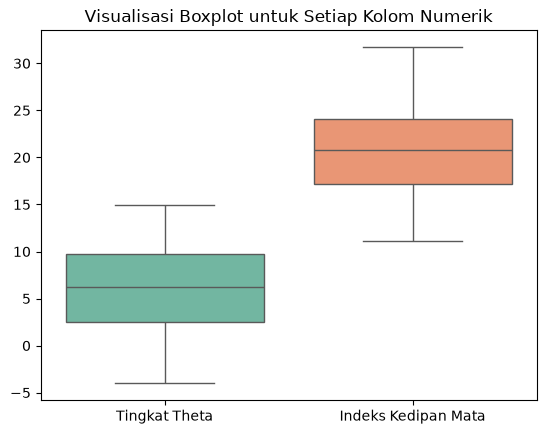

In [9]:
sns.boxplot(data=df[numeric_cols], palette='Set2')
plt.title('Visualisasi Boxplot untuk Setiap Kolom Numerik')
plt.show()

**Insight**: Grafik menunjukkan bahwa kedua fitur bersih dari outlier dan berdistribusi simetris, tetapi memiliki rentang skala nilai yang berbeda jauh. Tidak diperlukan penanganan outlier, namun wajib dilakukan feature scaling agar fitur berskala lebih besar tidak mendominasi perhitungan jarak pada model SVM.

### 3.4 Visualisasi distribusi data

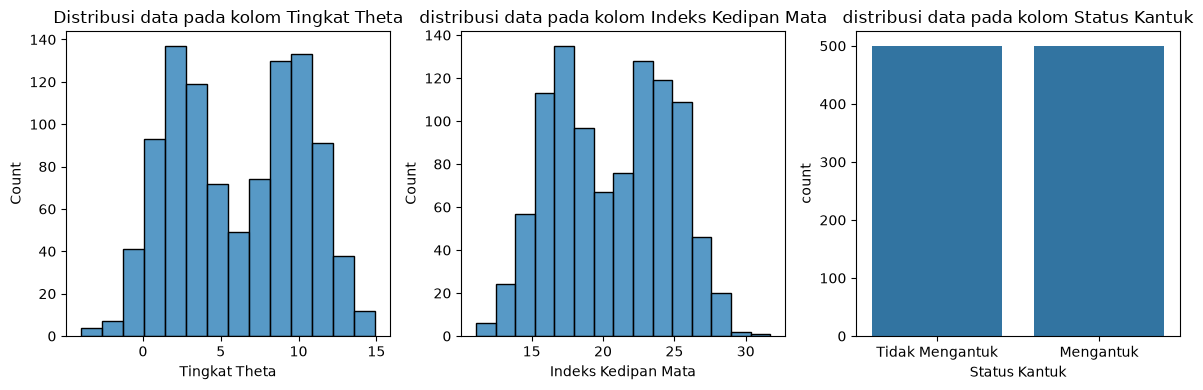

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

ax1 = axes[0]
sns.histplot(data=df, x='Tingkat Theta', ax=ax1)
ax1.set_title('Distribusi data pada kolom Tingkat Theta')

ax2 = axes[1]
sns.histplot(data=df, x='Indeks Kedipan Mata', ax=ax2)
ax2.set_title('distribusi data pada kolom Indeks Kedipan Mata')

ax3 = axes[2]
sns.countplot(data=df, x='Status Kantuk', ax=ax3)
ax3.set_title('distribusi data pada kolom Status Kantuk')

plt.tight_layout()
plt.show()

**Insight**: Grafik tersebut menunjukan Kedua fitur numerik memiliki distribusi dua puncak yang mengindikasikan adanya pemisahan pola antar kelas, sedangkan variabel target `Status Kantuk` terdistribusi seimbang sempurna dengan jumlah masing-masing 500 data.

### 3.5 Visualisasi data dengan Scatterplot

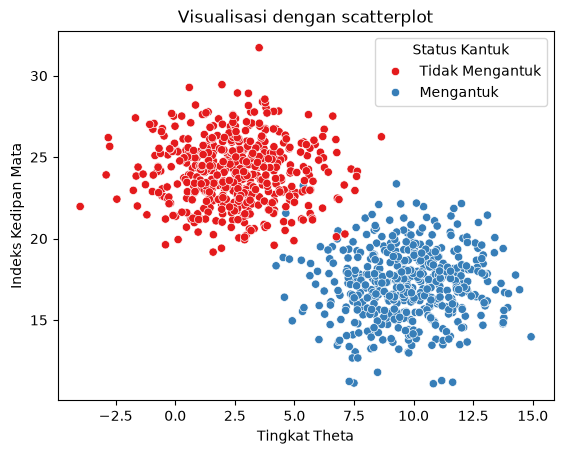

In [11]:
sns.scatterplot(data=df, x='Tingkat Theta', y='Indeks Kedipan Mata', palette='Set1', hue='Status Kantuk')
plt.title('Visualisasi dengan scatterplot')
plt.show()

**Insight**: Kedua kelas membentuk dua klaster yang terpisah secara linear dengan sedikit area tumpang tindih di bagian batas tengah, di mana kondisi mengantuk ditandai oleh tingkat theta yang tinggi dan indeks kedipan mata yang rendah.

### 3.6 Analisis korelasi antar kolom numerik

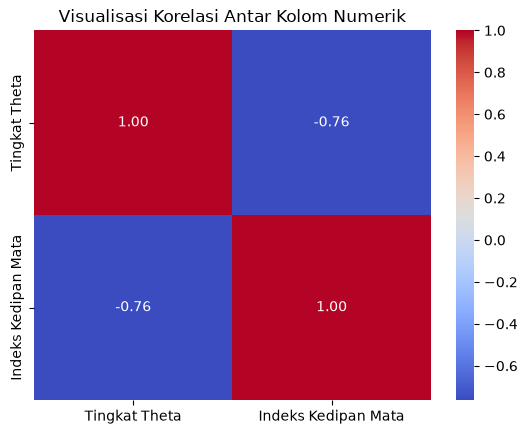

In [12]:
korelasi = df[numeric_cols].corr(method='pearson')
sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Visualisasi Korelasi Antar Kolom Numerik')
plt.show()

**Insight**: Grafik tersebut menunjukkan adanya hubungan korelasi yang tinggi antara fitur `Index Kedipan Mata` dan `Tingkat Theta` dengan nilai korelasi di $-0.79$.

---
## 4. Data Preprocessing

### 4.1 Encoding pada kolom target

In [13]:
df['Status Kantuk'] = pd.factorize(df['Status Kantuk'])[0]

print(f"kolom unik Status Kantuk: {df['Status Kantuk'].unique()}")

kolom unik Status Kantuk: [0 1]


### 4.2 Memisahkan kolom fitur($X$) dan kolom target ($Y$)

In [14]:
X = df.drop('Status Kantuk', axis=1)
y = df['Status Kantuk']

print(f"Bentuk X : {X.shape[0]} baris, {X.shape[1]} kolom")
print(f"Bentuk y : {y.shape[0]} label")

Bentuk X : 1000 baris, 2 kolom
Bentuk y : 1000 label


### 4.3 Membagi data uji dan data latih (80:20)

In [15]:
np.random.seed(43)
index = np.random.permutation(len(X))
batas = int(len(X) * 0.8)

X_train = X.iloc[index[:batas]]
X_test = X.iloc[index[batas:]]
y_train = y.iloc[index[:batas]]
y_test = y.iloc[index[batas:]]

print(f'Data Latih : {len(X_train)} Baris (80%)')
print(f'Data Uji : {len(X_test)} Baris (20%)')

Data Latih : 800 Baris (80%)
Data Uji : 200 Baris (20%)


### 4.4 Scalling pada kolom fitur dengan standarization

In [16]:
mean = X_train.mean()
std = X_train.std()
X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

X_train_scaled.describe()

,Tingkat Theta,Indeks Kedipan Mata
count,8.000000e+02,8.000000e+02
mean,1.409983e-16,-5.195844e-16
std,1.000000e+00,1.000000e+00
min,-2.213897e+00,-2.349797e+00
25%,-8.905342e-01,-8.507872e-01
50%,1.621425e-02,2.807085e-02
75%,8.770126e-01,8.543212e-01
max,2.155650e+00,2.757482e+00


### 4.4 Visualisasi setelah scalling

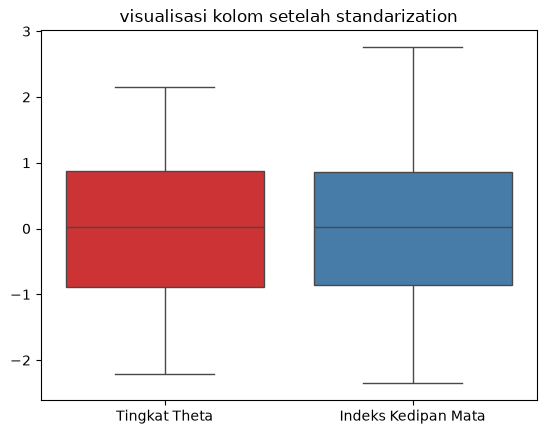

In [17]:
sns.boxplot(data=X_train_scaled, palette='Set1')
plt.title('visualisasi kolom setelah standarization')
plt.show()

**Insight**: Grafik tersebut menunjukkan bahwa kolom `Tingkat Theta` dan kolom `Index Kedipan Mata` telah berhasil di scaling dengan ditandai bobot skala yang kini telah seimbang antara kedua kolom.

---

## 5. Modelling

### 5.1 Membangun Algoritma Support Vehicle Machine (SVM)

In [ ]:
class SVM:
    def __init__(self, learning_rate=0.001, lambda_param=0.01, n_iters=1000):
        self.lr = learning_rate
        self.lambda_param = lambda_param
        self.n_iters = n_iters
        self.w = None
        self.b = None

    def fit(self, X, y):
        X = np.array(X)
        y_ = np.where(y <= 0, -1, 1)
        n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0

        for _ in range(self.n_iters):
            for idx, x_i in enumerate(X):
                condition = y_[idx] * (np.dot(x_i, self.w) - self.b) >= 1
                if condition:
                    self.w -= self.lr * (2 * self.lambda_param * self.w)
                else:
                    self.w -= self.lr * (2 * self.lambda_param * self.w - np.dot(x_i, y_[idx]))
                    self.b -= self.lr * y_[idx]

    def predict(self, X):
        approx = np.dot(X, self.w) - self.b
        return np.where(approx >= 0, 1, -1)

### 5.2 Pelatihan Model & Informasi Hyperplane

In [ ]:
model_svm = SVM(learning_rate=0.001, lambda_param=0.01, n_iters=1000)
model_svm.fit(X_train_scaled, y_train)

norma_w = np.linalg.norm(model_svm.w)
margin_width = 2 / norma_w

print("Bobot Fitur 1    :", round(model_svm.w[0], 4))
print("Bobot Fitur 2    :", round(model_svm.w[1], 4))
print("Nilai Bias       :", round(model_svm.b, 4))
print("Norma Bobot      :", round(norma_w, 4))
print("Lebar Margin     :", round(margin_width, 4))
print(f"\nPersamaan Hyperplane: {model_svm.w[0]:.4f}*X1 + ({model_svm.w[1]:.4f})*X2 - {model_svm.b:.4f} = 0")

Bobot Fitur 1                       : 1.1953
Bobot Fitur 2                       : -1.1359
Nilai Bias                          : 0.0660
Norma Bobot                         : 1.6490
Lebar Margin Optimal                : 1.2129

Persamaan Hyperplane:
1.1953 * X1 + (-1.1359) * X2 - (0.0660) = 0


### 5.3 Memprediksi Data Latih & Data Uji

In [ ]:
y_pred_train = model_svm.predict(X_train_scaled)
y_pred_test = model_svm.predict(X_test_scaled)

df_hasil = pd.DataFrame({
    "Label Aktual": np.where(y_test <= 0, -1, 1),
    "Label Prediksi": y_pred_test
})

print("10 Hasil Prediksi Data Testing:")
print(df_hasil.head(10))

10 Hasil Prediksi pada Data Testing:
   Label Aktual  Label Prediksi
0            -1              -1
1            -1              -1
2            -1              -1
3            -1              -1
4             1               1
5             1               1
6             1               1
7            -1              -1
8             1               1
9             1               1


---

## 6. Evaluation

### 6.1 Confusion Matrix & Metrik Evaluasi

In [21]:
def evaluation(y_true, y_pred):
    y_true_biner = np.where(np.asarray(y_true) <= 0, -1, 1)
    y_pred_biner = np.where(np.asarray(y_pred) <= 0, -1, 1)

    TP = int(np.sum((y_true_biner == 1) & (y_pred_biner == 1)))
    TN = int(np.sum((y_true_biner == -1) & (y_pred_biner == -1)))
    FP = int(np.sum((y_true_biner == -1) & (y_pred_biner == 1)))
    FN = int(np.sum((y_true_biner == 1) & (y_pred_biner == -1)))

    total = TP + TN + FP + FN
    accuracy = (TP + TN) / total if total > 0 else 0.0
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1_score = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0

    confusion_matrix = np.array([[TN, FP], [FN, TP]])

    return {"TP": TP, "TN": TN, "FP": FP, "FN": FN, "Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1-Score": f1_score, "Confusion Matrix": confusion_matrix}

eval_train = evaluation(y_train, y_pred_train)
eval_test = evaluation(y_test, y_pred_test)

df_evaluation = pd.DataFrame({
    "Metrik Evaluasi": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Data Training": [f"{eval_train['Accuracy']*100:.2f}%", f"{eval_train['Precision']*100:.2f}%", f"{eval_train['Recall']*100:.2f}%", f"{eval_train['F1-Score']*100:.2f}%"],
    "Data Testing": [f"{eval_test['Accuracy']*100:.2f}%", f"{eval_test['Precision']*100:.2f}%", f"{eval_test['Recall']*100:.2f}%", f"{eval_test['F1-Score']*100:.2f}%"]
})

print(df_evaluation)
print(f"\nConfusion Matrix Testing -> TN: {eval_test['TN']}, FP: {eval_test['FP']}, FN: {eval_test['FN']}, TP: {eval_test['TP']}")

  Metrik Evaluasi Data Training Data Testing
0        Accuracy        99.38%      100.00%
1       Precision        99.50%      100.00%
2          Recall        99.25%      100.00%
3        F1-Score        99.38%      100.00%

Confusion Matrix Testing -> TN: 101, FP: 0, FN: 0, TP: 99


### 6.2 Visualisasi Confusion Matrix dan Perbandingan Metrik

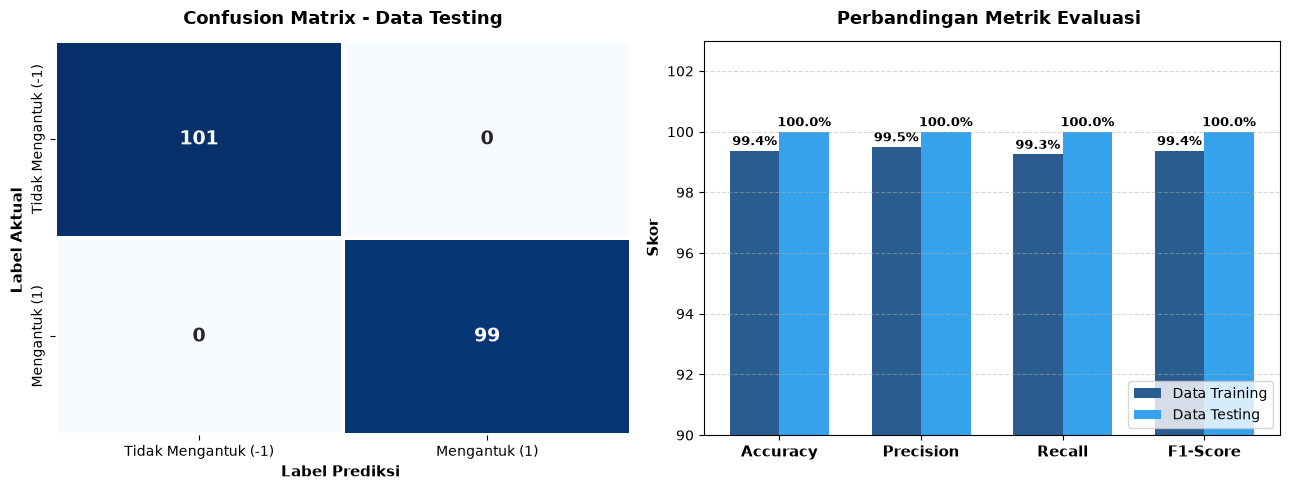

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

confusion_matrix_test = eval_test["Confusion Matrix"]
kelas_label = ["Tidak Mengantuk (-1)", "Mengantuk (1)"]

sns.heatmap(confusion_matrix_test, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=kelas_label, yticklabels=kelas_label, annot_kws={"size": 14, "weight": "bold"}, ax=axes[0], linewidths=1.5, linecolor="white")
axes[0].set_title("Confusion Matrix - Data Testing", fontsize=13, fontweight="bold", pad=12)
axes[0].set_xlabel("Label Prediksi ", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Label Aktual ", fontsize=11, fontweight="bold")

nama_metrik = ["Accuracy", "Precision", "Recall", "F1-Score"]
skor_train = [eval_train[m] * 100 for m in nama_metrik]
skor_test = [eval_test[m] * 100 for m in nama_metrik]

x_posisi = np.arange(len(nama_metrik))
lebar = 0.35

bar_train = axes[1].bar(x_posisi - lebar/2, skor_train, lebar, label="Data Training", color="#2b5c8f")
bar_test = axes[1].bar(x_posisi + lebar/2, skor_test, lebar, label="Data Testing", color="#36a2eb")

axes[1].set_ylim(90, 103)
axes[1].set_ylabel("Skor", fontsize=11, fontweight="bold")
axes[1].set_title("Perbandingan Metrik Evaluasi ", fontsize=13, fontweight="bold", pad=12)
axes[1].set_xticks(x_posisi)
axes[1].set_xticklabels(nama_metrik, fontsize=11, fontweight="bold")
axes[1].legend(loc="lower right")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

for bar in list(bar_train) + list(bar_test):
    tinggi = bar.get_height()
    axes[1].annotate(f"{tinggi:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, tinggi), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9.5, fontweight="bold")

plt.tight_layout()
plt.show()

### 6.3 Visualisasi Batas Keputusan Hyperplane dan Margin

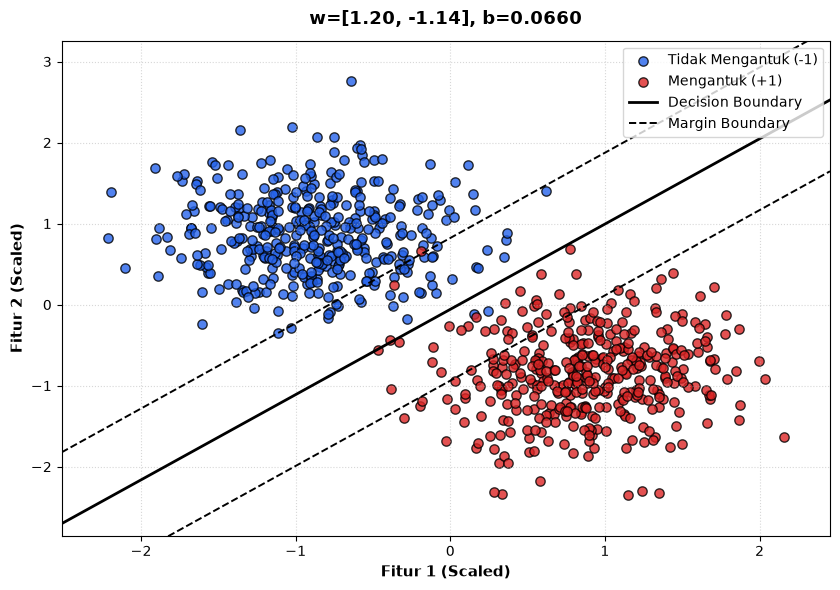

In [23]:
def hyperplane_value(x, w, b, offset):
    return (-w[0] * x + b + offset) / w[1]

fig, ax = plt.subplots(figsize=(8.5, 6))

X_visualisasi = np.asarray(X_train_scaled, dtype=float)
y_visualisasi = np.where(np.asarray(y_train) <= 0, -1, 1)

tidak_kantuk = (y_visualisasi == -1)
mask_kantuk = (y_visualisasi == 1)

ax.scatter(X_visualisasi[tidak_kantuk, 0], X_visualisasi[tidak_kantuk, 1], c="#2563eb", edgecolors="k", s=45, alpha=0.8, label="Tidak Mengantuk (-1)")

ax.scatter(X_visualisasi[mask_kantuk, 0], X_visualisasi[mask_kantuk, 1], c="#dc2626", edgecolors="k", s=45, alpha=0.8, label="Mengantuk (+1)")

x0_min, x0_max = X_visualisasi[:, 0].min() - 0.3, X_visualisasi[:, 0].max() + 0.3
x0_values = np.linspace(x0_min, x0_max, 200)

x1_decision = hyperplane_value(x0_values, model_svm.w, model_svm.b, 0)
x1_margin_positif = hyperplane_value(x0_values, model_svm.w, model_svm.b, 1)
x1_margin_negatif = hyperplane_value(x0_values, model_svm.w, model_svm.b, -1)

ax.plot(x0_values, x1_decision, "k-", lw=2, label="Decision Boundary ")
ax.plot(x0_values, x1_margin_positif, "k--", lw=1.4, label="Margin Boundary ")
ax.plot(x0_values, x1_margin_negatif, "k--", lw=1.4)

x1_min, x1_max = X_visualisasi[:, 1].min() - 0.5, X_visualisasi[:, 1].max() + 0.5
ax.set_xlim(x0_min, x0_max)
ax.set_ylim(x1_min, x1_max)

ax.set_title(f"w=[{model_svm.w[0]:.2f}, {model_svm.w[1]:.2f}], b={model_svm.b:.4f}", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Fitur 1 (Scaled)", fontsize=11, fontweight="bold")
ax.set_ylabel("Fitur 2 (Scaled)", fontsize=11, fontweight="bold")
ax.legend(loc="upper right", frameon=True)
ax.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

---

## 7. GUI (Graphical User Interface)

In [25]:
import tkinter as tk
from tkinter import ttk, messagebox

def jalankan_gui_svm():
    root = tk.Tk()
    root.title("Sistem Deteksi Status Kantuk Pengemudi")
    root.geometry("460x500")
    root.configure(bg="#f8fafc")
    root.resizable(False, False)

    header_frame = tk.Frame(root, bg="#1e293b", height=65)
    header_frame.pack(fill="x")
    tk.Label(
        header_frame,
        text="SISTEM DETEKSI KANTUK PENGEMUDI",
        font=("Segoe UI", 13, "bold"), fg="white", bg="#1e293b", pady=8
    ).pack()
    tk.Label(
        header_frame,
        text="Klasifikasi Berdasarkan Tingkat Otak Theta & Indeks Kedipan Mata",
        font=("Segoe UI", 9), fg="#cbd5e1", bg="#1e293b"
    ).pack(pady=(0, 8))

    main_panel = tk.Frame(root, bg="#ffffff", bd=1, relief="solid", padx=20, pady=16)
    main_panel.pack(fill="both", expand=True, padx=16, pady=14)

    tk.Label(
        main_panel, text="1. Input Parameter Sensor Fisiologis",
        font=("Segoe UI", 11, "bold"), bg="#ffffff", fg="#0f172a"
    ).pack(anchor="w", pady=(0, 8))

    tk.Label(
        main_panel, text="Tingkat Otak Theta :",
        font=("Segoe UI", 9, "bold"), bg="#ffffff", fg="#334155"
    ).pack(anchor="w")
    entry_theta = ttk.Entry(main_panel, font=("Segoe UI", 11))
    entry_theta.pack(fill="x", pady=(3, 10))

    tk.Label(
        main_panel, text="Indeks Kedipan Mata :",
        font=("Segoe UI", 9, "bold"), bg="#ffffff", fg="#334155"
    ).pack(anchor="w")
    entry_kedipan = ttk.Entry(main_panel, font=("Segoe UI", 11))
    entry_kedipan.pack(fill="x", pady=(3, 14))

    def proses_prediksi():
        try:
            theta_raw = float(entry_theta.get().strip())
            kedipan_raw = float(entry_kedipan.get().strip())
        except ValueError:
            messagebox.showerror("Input Tidak Valid")
            return

        input_raw = np.array([theta_raw, kedipan_raw], dtype=float)
        input_scaled = (input_raw - np.asarray(mean, dtype=float)) / np.asarray(std, dtype=float)
        pred_kelas = int(model_svm.predict(input_scaled))

        if pred_kelas == 1:
            hasil_box.configure(bg="#fef2f2")
            lbl_status.configure(text="Mengantuk (+1)", bg="#fef2f2", fg="#dc2626")
            lbl_rekomendasi.configure(
                text="Terdeteksi kelelahan",
                bg="#fef2f2", fg="#991b1b"
            )
        else:
            hasil_box.configure(bg="#f0fdf4")
            lbl_status.configure(text="Tidak Mengantuk (-1)", bg="#f0fdf4", fg="#15803d")
            lbl_rekomendasi.configure(
                text="Pengemudi berada dalam kondisi terjaga",
                bg="#f0fdf4", fg="#166534"
            )

    def reset_form():
        entry_theta.delete(0, tk.END)
        entry_kedipan.delete(0, tk.END)
        hasil_box.configure(bg="#f1f5f9")
        lbl_status.configure(text="Belum Dianalisis", bg="#f1f5f9", fg="#475569")
        lbl_rekomendasi.configure(
            text="Masukkan nilai sensor terlebih dahulu",
            bg="#f1f5f9", fg="#64748b"
        )

    btn_frame = tk.Frame(main_panel, bg="#ffffff")
    btn_frame.pack(fill="x", pady=(0, 14))

    tk.Button(
        btn_frame, text="Deteksi Status Kantuk", font=("Segoe UI", 10, "bold"),
        bg="#2563eb", fg="white", activebackground="#1d4ed8", activeforeground="white",
        relief="flat", pady=7, command=proses_prediksi
    ).pack(fill="x", pady=(0, 6))

    tk.Button(
        btn_frame, text="Reset Input", font=("Segoe UI", 9),
        bg="#e2e8f0", fg="#334155", relief="flat", pady=5, command=reset_form
    ).pack(fill="x")

    tk.Label(
        main_panel, text="2. Hasil Keputusan",
        font=("Segoe UI", 11, "bold"), bg="#ffffff", fg="#0f172a"
    ).pack(anchor="w", pady=(4, 6))

    hasil_box = tk.Frame(main_panel, bg="#f1f5f9", bd=1, relief="solid", padx=12, pady=14)
    hasil_box.pack(fill="x")

    lbl_status = tk.Label(
        hasil_box, text="Belum Dianalisis",
        font=("Segoe UI", 13, "bold"), bg="#f1f5f9", fg="#475569"
    )
    lbl_status.pack()

    lbl_rekomendasi = tk.Label(
        hasil_box, text="Masukkan nilai sensor terlebih dahulu",
        font=("Segoe UI", 9), bg="#f1f5f9", fg="#64748b", wraplength=360, justify="center"
    )
    lbl_rekomendasi.pack(pady=(4, 0))

    root.mainloop()

jalankan_gui_svm()

---

## 8. Conclusion

Berdasarkan seluruh tahapan pengerjaan mulai dari *Business Understanding* sampai *GUI*, diperoleh kesimpulan akhir sebagai berikut:

1. **Kualitas dan Karakteristik Dataset:**
   Dataset memiliki struktur yang bersih tanpa adanya nilai kosong (missing values), duplikasi data, maupun outlier pada fitur Tingkat Theta dan Indeks Kedipan Mata. Distribusi variabel target Status Kantuk terbagi secara seimbang antara kelas Mengantuk dan Tidak Mengantuk, sementara visualisasi sebaran data menunjukkan pemisahan klaster yang jelas meskipun kedua fitur memiliki rentang skala nilai yang berbeda.

2. **Pola Fisiologis Status Kantuk Pengemudi:**
   Kelelahan dan rasa kantuk pengemudi berkorelasi positif dengan peningkatan aktivitas gelombang otak *Tingkat Theta* serta berkorelasi negatif dengan *Indeks Kedipan Mata* per menit. Kedua fitur fisiologis ini memiliki pemisahan ruang fitur yang jelas sehingga sangat efektif diklasifikasikan menggunakan pendekatan batas lurus.

3. **Keberhasilan Pemodelan SVM:**
   Implementasi algoritma *Support Vector Machine* (SVM) menggunakan optimasi *Gradient Descent* pada *Hinge Loss* dan regularisasi berhasil menemukan *hyperplane* pemisah dengan margin yang lebar. Tanda koefisien bobot fitur pertama yang positif dan bobot fitur kedua yang negatif membuktikan bahwa model mempelajari arah hubungan secara tepat. Hasil pengujian pada data *testing* menunjukkan konsistensi yang tinggi tanpa adanya *overfitting* maupun kegagalan deteksi pada kelas positif.